# 2. Themes and trends

What do shoppers praise or complain about, how does it differ between local and international shoppers, and how has it changed since 2016?

### Table of contents
2.1 Setup  
2.2 Overview  
2.3 Themes  
2.4 Positive or negative  
2.5 Themes by store type  
2.6 International vs local shoppers  
2.7 Change over time  
2.8 Effect of staff-named reviews  
2.9 Save tables for Power BI  
2.10 Sample for a manual check

## 2.1 Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
df = pd.read_csv('../data_private/reviews_clean.csv', parse_dates=['date', 'month'])
txt = df[df['has_text']].copy()
print(len(df), 'reviews,', len(txt), 'with text')

16705 reviews, 12502 with text


## 2.2 Overview

In [2]:
overview = df.groupby(['store_group', 'store']).agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean'),
                                                     staff_named=('staff_named', 'mean')).round(2)
overview.sort_values('reviews', ascending=False)

reviews  avg_rating  staff_named
store_group       store                                                     
Sephora           Sephora, Champs-Élysées      9799        4.45         0.17
Brand boutique    Guerlain, Champs-Élysées     1736        4.50         0.07
Airport duty free CDG Terminal 1 duty free     1655        4.87         0.29
Department store  Printemps Haussmann          1011        4.89         0.31
                  Galeries Lafayette            579        4.47         0.04
Brand boutique    Chanel, Champs-Élysées        323        4.62         0.12
                  Kurkdjian, rue d'Alger        283        4.24         0.07
Department store  Samaritaine                   275        4.48         0.14
Airport duty free CDG Terminal 3 duty free      236        3.86         0.11
Brand boutique    Chanel, Marais                222        4.36         0.08
                  Kurkdjian, Marais             187        4.64         0.17
Department store  Le Bon Marché                 181        4.46         0.06
                  Printemps Maison Beauté       134        4.40         0.34
Brand boutique    Dior, 30 Montaigne             84        4.20         0.13

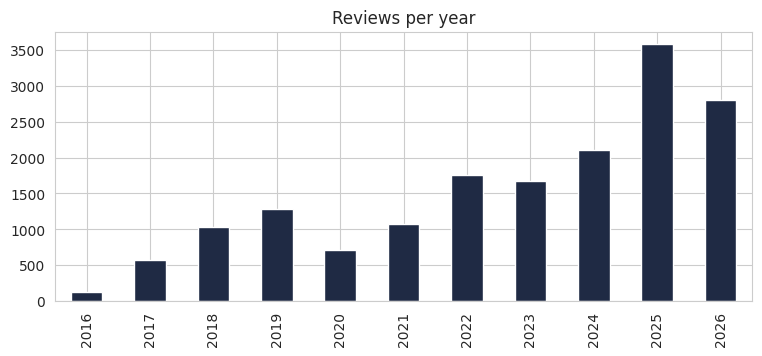

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
df.groupby('year').size().plot(kind='bar', ax=ax, color='#1f2a44')
ax.set_title('Reviews per year')
ax.set_xlabel('')
plt.show()

## 2.3 Themes

Each review is tagged with the themes it talks about, using keywords in the English text.  
A review can mention several themes. Keywords were checked on samples to remove words with a second meaning (for example *genuine* as in "genuine kindness", or *can't wait to come back*). Staff are split into two topics, praise and complaints, because "service" alone is used both ways.

In [4]:
themes = {
    'Price and value': r'\b(?:prices?|pricey|expensive|cheap|cheaper|overpriced|value for money|discount|promotion)\b',
    'Warm, expert advice': r'(?<!not )(?<!n.t )\b(?:helpful|friendly|knowledgeable|attentive|welcoming|patient|great advice|excellent advice|good advice|expert advice)\b',
    'Rude or unhelpful staff': r'\b(?:rude|rudely|ignored|unhelpful|arrogant|condescending|unfriendly|unpleasant|disrespectful|contemptuous|judged|looked down|unwelcom\w*|not welcom\w*|not helpful|no one (?:came|helped|served)|nobody (?:came|helped|served))\b',
    'Language spoken': r'\b(?:english|language|fluent|mandarin|translat\w*)\b|speaks? (?:french|chinese|arabic|russian|spanish|italian|japanese|korean)',
    'Tax refund': r'tax refund|tax-free|tax free|detax|d[ée]taxe|\bvat\b|global blue',
    'Queues and crowding': r'\b(?:queues?|queuing|waited|waiting (?:time|for|in|line)|long wait|wait(?:ing)? time|crowded|crowds?|packed|long line)\b',
    'Stock availability': r'out of stock|in stock|\bstock\b|not available|unavailable|didn.t have|did not have|couldn.t find|could not find',
    'Authenticity and trust': r'\b(?:fake|authentic|authenticity|counterfeit|scam|scammed|expired|tampered)\b',
    'Gifts, samples, engraving': r'\b(?:gift ?wrap\w*|wrapping|samples?|engrav\w*|gift box|packaging)\b'}

for name, pattern in themes.items():
    txt[name] = txt['text_en'].str.contains(pattern, case=False, regex=True)

mentions = txt[list(themes)].mean().sort_values(ascending=False).mul(100).round(1)
mentions

Warm, expert advice          32.2
Gifts, samples, engraving     3.9
Queues and crowding           3.9
Price and value               3.7
Rude or unhelpful staff       2.9
Stock availability            1.2
Tax refund                    0.8
Language spoken               0.7
Authenticity and trust        0.3
dtype: float64

## 2.4 Positive or negative

The star rating gives the tone: 4-5 stars positive, 3 mixed, 1-2 negative.  
For each theme: share of reviews mentioning it that are negative, and how often it appears in negative reviews.

In [5]:
txt['tone'] = pd.cut(txt['rating'], [0, 2, 3, 5], labels=['Negative', 'Mixed', 'Positive'])

def theme_table(data):
    rows = []
    for t in themes:
        sub = data[data[t]]
        rows.append({'theme': t, 'mentions': len(sub),
                     'pct_of_reviews': len(sub) / len(data) * 100,
                     'pct_positive': (sub['tone'] == 'Positive').mean() * 100,
                     'pct_negative': (sub['tone'] == 'Negative').mean() * 100,
                     'share_of_complaints': sub['tone'].eq('Negative').sum() / data['tone'].eq('Negative').sum() * 100,
                     'negative_mentions': int(sub['tone'].eq('Negative').sum()),
                     'negative_reviews': int(data['tone'].eq('Negative').sum())})
    return pd.DataFrame(rows).round(1)

theme_table(txt).sort_values('pct_negative', ascending=False)

,theme,mentions,pct_of_reviews,pct_positive,pct_negative,share_of_complaints,negative_mentions,negative_reviews
2,Rude or unhelpful staff,368,2.9,9.8,81.8,25.8,301,1165
6,Stock availability,145,1.2,49.7,41.4,5.2,60,1165
7,Authenticity and trust,38,0.3,60.5,36.8,1.2,14,1165
8,"Gifts, samples, engraving",490,3.9,62.7,32.7,13.7,160,1165
3,Language spoken,93,0.7,65.6,32.3,2.6,30,1165
0,Price and value,462,3.7,61.9,29.0,11.5,134,1165
4,Tax refund,94,0.8,62.8,28.7,2.3,27,1165
5,Queues and crowding,485,3.9,62.5,23.3,9.7,113,1165
1,"Warm, expert advice",4031,32.2,96.2,2.3,8.1,94,1165


## 2.5 Themes by store type

In [6]:
by_group = pd.concat([theme_table(g).assign(store_group=k) for k, g in txt.groupby('store_group')])
by_group.pivot(index='theme', columns='store_group', values='pct_negative')

store_group,Airport duty free,Brand boutique,Department store,Sephora
theme,,,,
Authenticity and trust,66.7,55.6,30.0,25.0
"Gifts, samples, engraving",33.3,24.1,37.3,36.2
Language spoken,10.0,25.0,37.5,37.3
Price and value,42.6,41.1,17.4,27.2
Queues and crowding,26.3,43.2,15.3,23.0
Rude or unhelpful staff,100.0,87.7,85.0,78.9
Stock availability,27.3,41.2,29.2,46.2
Tax refund,33.3,15.4,13.5,50.0
"Warm, expert advice",0.7,3.7,1.5,2.6


## 2.6 International vs local shoppers

In [7]:
by_lang = pd.concat([theme_table(g).assign(language_group=k) for k, g in txt.groupby('language_group')])
by_lang.pivot(index='theme', columns='language_group', values='pct_of_reviews')

language_group,English,French,Other languages
theme,,,
Authenticity and trust,0.6,0.2,0.4
"Gifts, samples, engraving",4.2,4.0,2.7
Language spoken,1.4,0.2,2.9
Price and value,5.1,2.5,8.7
Queues and crowding,4.7,3.5,4.9
Rude or unhelpful staff,3.6,2.9,1.8
Stock availability,1.4,1.1,0.8
Tax refund,2.0,0.2,1.8
"Warm, expert advice",28.5,35.1,21.3


In [8]:
by_lang.pivot(index='theme', columns='language_group', values='pct_negative')

language_group,English,French,Other languages
theme,,,
Authenticity and trust,46.7,29.4,33.3
"Gifts, samples, engraving",19.1,39.1,13.5
Language spoken,43.2,41.2,17.9
Price and value,29.1,39.0,11.0
Queues and crowding,14.5,27.5,21.2
Rude or unhelpful staff,87.4,80.2,76.0
Stock availability,13.9,53.1,27.3
Tax refund,24.5,70.6,8.3
"Warm, expert advice",1.7,2.6,1.0


In [9]:
lang_rating = df[df['has_text']].groupby(['store_group', 'language_group'])['rating'].agg(['size', 'mean']).round(2)
lang_rating

size  mean
store_group       language_group             
Airport duty free English           574  4.74
                  French            987  4.79
                  Other languages   157  4.77
Brand boutique    English           460  4.36
                  French           1244  4.36
                  Other languages   240  4.59
Department store  English           493  4.62
                  French           1588  4.69
                  Other languages    86  4.41
Sephora           English          1097  4.38
                  French           4705  4.44
                  Other languages   871  4.58

## 2.7 Change over time

Events checked against official sources (see `data/events.csv`).

In [10]:
events = pd.DataFrame([
    ['2018-11-17', '', 'Unrest', 'Yellow vest protests begin (Saturday marches, often on the Champs-Élysées)', 'https://www.publicsenat.fr/article/politique/la-crise-des-gilets-jaunes-en-dix-dates-139738'],
    ['2019-03-16', '', 'Unrest', 'Shops looted and burned on the Champs-Élysées', 'https://www.publicsenat.fr/actualites/non-classe/saccage-des-champs-elysees-80-enseignes-touchees-le-premier-ministre-interpelle'],
    ['2019-12-05', '', 'Unrest', 'Pension-reform strikes start; Paris metro and trains largely stopped', 'https://www.publicsenat.fr/actualites/politique/retraites-la-greve-dure-dans-les-transports-nouvelle-epreuve-de-force-en-vue'],
    ['2020-03-17', '2020-05-11', 'Health', 'Lockdown 1: non-essential shops closed', 'https://www.insee.fr/fr/statistiques/4797670'],
    ['2020-10-30', '2020-11-28', 'Health', 'Lockdown 2: non-essential shops closed', 'https://www.info.gouv.fr/discours/11902-point-de-situation-sur-la-lutte-contre-la-covid-19'],
    ['2021-01-01', '', 'Policy', 'Tax refund minimum cut from EUR 175.01 to EUR 100.01', 'https://www.douane.gouv.fr/fiche/la-detaxe-en-france-pour-les-touristes-pablo'],
    ['2021-04-03', '2021-05-19', 'Health', 'Lockdown 3: shops reopen 19 May', 'https://www.economie.gouv.fr/commerce-conditions-reouverture'],
    ['2021-06-09', '', 'Tourism', 'France reopens to vaccinated foreign tourists', 'https://diplomatie.gouv.fr/en/coming-to-france/coming-to-france-your-covid-19-questions-answered/coronavirus-statements/article/reopening-france-s-borders-from-9-june-4-jun-2021'],
    ['2022-03-15', '', 'Policy', 'EU bans luxury goods exports to Russia', 'https://finance.ec.europa.eu/news/ukraine-eu-agrees-fourth-package-restrictive-measures-against-russia-2022-03-15_en'],
    ['2022-07-12', '', 'Currency', 'Euro falls to parity with the US dollar (cheaper Paris for Americans)', 'https://www.aljazeera.com/economy/2022/7/12/euro-hits-us-dollar-parity-for-first-time-in-20-years'],
    ['2023-01-08', '', 'Tourism', 'China ends quarantine on return; Chinese can travel abroad again', 'https://www.aljazeera.com/news/2023/1/8/china-reopens-borders-to-quarantine-free-travel'],
    ['2023-03-01', '', 'Tourism', 'China resumes group tours to France (March 2023)', 'https://skift.com/2023/08/10/china-resumes-outbound-group-trips-to-u-s-uk-japan'],
    ['2024-07-26', '2024-08-11', 'Big event', 'Paris Olympic Games', 'https://www.info.gouv.fr/grand-dossier/paris-2024-olympic-and-paralympic-games'],
    ['2025-10-12', '', 'Policy', 'EU Entry/Exit System starts at borders', 'https://home-affairs.ec.europa.eu/news/new-entryexit-system-went-live-12-october-2025-10-13_en']],
    columns=['start', 'end', 'type', 'event', 'source'])
events

,start,end,type,event,source
0,2018-11-17,,Unrest,"Yellow vest protests begin (Saturday marches, ...",https://www.publicsenat.fr/article/politique/l...
1,2019-03-16,,Unrest,Shops looted and burned on the Champs-Élysées,https://www.publicsenat.fr/actualites/non-clas...
2,2019-12-05,,Unrest,Pension-reform strikes start; Paris metro and ...,https://www.publicsenat.fr/actualites/politiqu...
3,2020-03-17,2020-05-11,Health,Lockdown 1: non-essential shops closed,https://www.insee.fr/fr/statistiques/4797670
4,2020-10-30,2020-11-28,Health,Lockdown 2: non-essential shops closed,https://www.info.gouv.fr/discours/11902-point-...
5,2021-01-01,,Policy,Tax refund minimum cut from EUR 175.01 to EUR ...,https://www.douane.gouv.fr/fiche/la-detaxe-en-...
6,2021-04-03,2021-05-19,Health,Lockdown 3: shops reopen 19 May,https://www.economie.gouv.fr/commerce-conditio...
7,2021-06-09,,Tourism,France reopens to vaccinated foreign tourists,https://diplomatie.gouv.fr/en/coming-to-france...
8,2022-03-15,,Policy,EU bans luxury goods exports to Russia,https://finance.ec.europa.eu/news/ukraine-eu-a...
9,2022-07-12,,Currency,Euro falls to parity with the US dollar (cheap...,https://www.aljazeera.com/economy/2022/7/12/eu...


In [11]:
yearly = df.groupby(['year', 'language_group']).agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean')).round(2).reset_index()
yearly.pivot(index='year', columns='language_group', values='reviews')

language_group,English,French,No text,Other languages
year,,,,
2016,23,32,55,10
2017,59,165,312,38
2018,94,250,597,86
2019,139,339,689,116
2020,48,257,360,40
2021,91,484,437,65
2022,225,790,567,172
2023,264,887,393,131
2024,406,1332,229,141


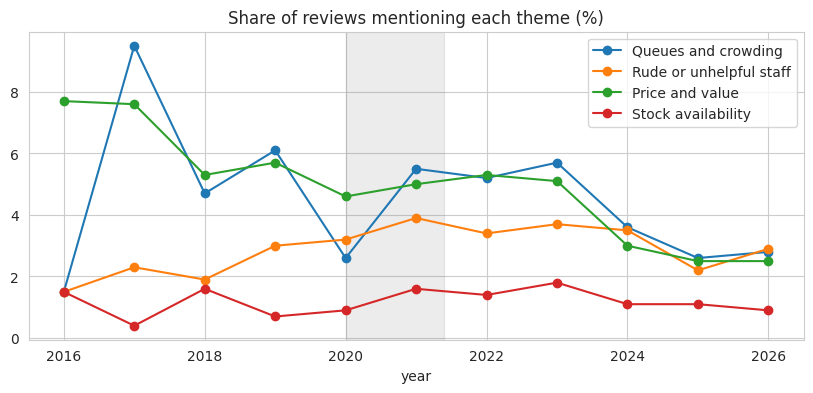

In [12]:
theme_year = txt.groupby('year')[list(themes)].mean().mul(100).round(1)
fig, ax = plt.subplots(figsize=(10, 4))
theme_year[['Queues and crowding', 'Rude or unhelpful staff', 'Price and value', 'Stock availability']].plot(ax=ax, marker='o')
ax.set_title('Share of reviews mentioning each theme (%)')
ax.axvspan(2020, 2021.4, color='grey', alpha=0.15)
plt.show()

## 2.8 Effect of staff-named reviews

In [13]:
staff = df[df['has_text']].groupby(['store_group', 'staff_named'])['rating'].agg(['size', 'mean']).round(2)
staff

size  mean
store_group       staff_named            
Airport duty free False        1213  4.69
                  True          505  4.99
Brand boutique    False        1712  4.31
                  True          232  4.95
Department store  False        1737  4.58
                  True          430  4.98
Sephora           False        5049  4.29
                  True         1624  4.95

In [14]:
staff_year = df[df['has_text']].groupby('year')['staff_named'].mean().mul(100).round(1)
staff_year

year
2016     0.0
2017     0.4
2018     1.9
2019     1.2
2020     5.2
2021     6.2
2022    11.1
2023    16.1
2024    25.4
2025    30.3
2026    35.7
Name: staff_named, dtype: float64

## 2.9 Save tables for Power BI

Only aggregated numbers are published. No review text, no reviewer details.

In [15]:
out = '../data/'
store_summary = df.groupby(['store_group', 'store']).agg(
    reviews=('rating', 'size'), with_text=('has_text', 'sum'), avg_rating=('rating', 'mean'),
    pct_negative=('rating', lambda r: (r <= 2).mean() * 100), pct_staff_named=('staff_named', lambda s: s.mean() * 100),
    pct_international=('language_group', lambda l: l.isin(['English', 'Other languages']).sum() / l.ne('No text').sum() * 100)).round(2)
store_summary['avg_rating_without_staff_named'] = df[~df['staff_named']].groupby(['store_group', 'store'])['rating'].mean().round(2)
store_summary.reset_index().to_csv(out + 'store_summary.csv', index=False)

# themes per store and language group
long = []
for (g, s, l), part in txt.groupby(['store_group', 'store', 'language_group']):
    long.append(theme_table(part).assign(store_group=g, store=s, language_group=l, reviews_with_text=len(part)))
pd.concat(long).drop(columns=['pct_of_reviews', 'pct_positive', 'pct_negative', 'share_of_complaints']).to_csv(out + 'themes.csv', index=False)

# ratings per year, store and language group
yearly = df.groupby(['year', 'store_group', 'store', 'language_group']).agg(
    reviews=('rating', 'size'), rating_sum=('rating', 'sum'), negative=('rating', lambda r: (r <= 2).sum()),
    staff_named=('staff_named', 'sum')).reset_index()
yearly['rating_sum_staff_named'] = df[df['staff_named']].groupby(['year', 'store_group', 'store', 'language_group'])['rating'].sum().reindex(
    pd.MultiIndex.from_frame(yearly[['year', 'store_group', 'store', 'language_group']])).fillna(0).values
yearly.to_csv(out + 'yearly.csv', index=False)

ty = []
for (y, g), part in txt.groupby(['year', 'store_group']):
    for t in themes:
        ty.append({'year': y, 'store_group': g, 'theme': t, 'reviews_with_text': len(part),
                   'mentions': int(part[t].sum()), 'negative_mentions': int((part[t] & part['tone'].eq('Negative')).sum())})
pd.DataFrame(ty).to_csv(out + 'themes_yearly.csv', index=False)
events.to_csv(out + 'events.csv', index=False)

# tagged reviews for notebook 3 (private, contains text)
txt.to_csv('../data_private/reviews_tagged.csv', index=False)
print('saved')

/sessions/rcw-01gsp127tujmdcjdmpt4cxqy/tmp/ipykernel_11/330867913.py:11: RuntimeWarning: invalid value encountered in scalar divide
  'share_of_complaints': sub['tone'].eq('Negative').sum() / data['tone'].eq('Negative').sum() * 100,
/sessions/rcw-01gsp127tujmdcjdmpt4cxqy/tmp/ipykernel_11/330867913.py:11: RuntimeWarning: invalid value encountered in scalar divide
  'share_of_complaints': sub['tone'].eq('Negative').sum() / data['tone'].eq('Negative').sum() * 100,


saved


## 2.10 Sample for a manual check

100 random reviews with the themes found. They are read by hand to see how often the keyword tagging is right. The sample stays private because it contains review text.

In [16]:
sample = txt.sample(100, random_state=7)[['reviewId', 'store', 'rating', 'text_en'] + list(themes)]
sample.to_csv('../data_private/manual_check_sample.csv', index=False)
len(sample)

100